# Importação dos Dados



```
dados/                     
  ├── metadata.csv            # uma linha por áudio original
  ├── audios/                 # todos os áudios em WAV mono 16 kHz
  │   ├── P001_acender_luz_r1.wav        
  │   ├── P001_acender_luz_r2.wav
  │   ├── ...
  │   └── C0001_common_voice_pt_<id>.wav
  └── musan/
      └── noise/              # ruídos do MUSAN (só a parte "noise")
          ├── free-sound/
          └── sound-bible/
```


In [ ]:
from google.colab import drive; drive.mount('/content/drive')
!unzip -q /content/drive/MyDrive/""SEU CAMINHO PARA OS DADOS"" -d /content

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Treinamento da Baseline
Regressão logística sobre estatísticas de coeficientes cepstrais de Mel (MFCC),
com rejeição de previsões abaixo de um limiar escolhido exclusivamente na validação.

### Pipeline:
padronização -> divisão por locutor -> ruído por SNR -> MFCC -> treino -> limiar na validação

In [ ]:
import os, glob, time
import numpy as np, pandas as pd, librosa
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, log_loss

SEED = 42
SR, DUR = 16000, 2.0
N = int(SR * DUR)
SNRS = [20, 10, 0]
AUDIO_DIR, META = "dados/audios", "dados/metadata.csv"
NOISE_DIR, OUT = "dados/musan/noise", "saida"
os.makedirs(OUT, exist_ok=True)
rng = np.random.default_rng(SEED)

## 1. Padronização

In [ ]:
def carregar(caminho):
    y, _ = librosa.load(caminho, sr=SR, mono=True)          # mono, 16 kHz
    y, _ = librosa.effects.trim(y, top_db=30)               # tira silêncio das pontas
    if len(y) >= N:                                         # duração fixa de 2 s
        s = (len(y) - N) // 2
        y = y[s:s + N]
    else:
        pad = N - len(y)
        y = np.pad(y, (pad // 2, pad - pad // 2))
    return 0.9 * y / (np.max(np.abs(y)) + 1e-9)             # normaliza o pico

## 2. Divisão por Locutor

60% Treino, 20% Validação, 20% Teste

In [ ]:
meta = pd.read_csv(META)
# Divide separadamente os locutores do grupo (comandos) e os do Common Voice (negativos),
# para que treino, validação e teste recebam as duas classes.
particao = {}
for _, grupo in meta.groupby("tipo"):
    locutores = np.array(sorted(grupo["locutor"].unique()))
    rng.shuffle(locutores)
    a, b = int(round(0.6 * len(locutores))), int(round(0.8 * len(locutores)))
    particao.update({l: "treino" for l in locutores[:a]})
    particao.update({l: "val" for l in locutores[a:b]})
    particao.update({l: "teste" for l in locutores[b:]})
meta["particao"] = meta["locutor"].map(particao)
meta.to_csv(f"{OUT}/divisao.csv", index=False)
print(meta.groupby(["particao", "tipo"]).agg(audios=("arquivo", "size"), locutores=("locutor", "nunique")))

                   audios  locutores
particao tipo                       
teste    comando       36          3
         negativo      33         11
treino   comando       96          8
         negativo      99         33
val      comando       36          3
         negativo      33         11


## 3. Ruídos divididos por Partição

In [ ]:
ruidos = sorted(glob.glob(f"{NOISE_DIR}/**/*.wav", recursive=True))
if len(ruidos) < 5:
    raise FileNotFoundError(f"Poucos ruídos em {NOISE_DIR} ({len(ruidos)}). Baixe o MUSAN (ou só a parte 'noise') antes.")
rng.shuffle(ruidos)
k = len(ruidos)
ruidos_part = {"treino": ruidos[:int(0.6 * k)],
               "val": ruidos[int(0.6 * k):int(0.8 * k)],
               "teste": ruidos[int(0.8 * k):]}

def misturar(y, arquivo_ruido, snr_db):
    r, _ = librosa.load(arquivo_ruido, sr=SR, mono=True)
    if len(r) < N:
        r = np.tile(r, N // len(r) + 1)
    s = rng.integers(0, len(r) - N + 1)
    r = r[s:s + N]
    voz = y[np.abs(y) > 0.02 * np.max(np.abs(y))]           # potência só do trecho com voz
    p_voz, p_ruido = np.mean(voz ** 2), np.mean(r ** 2) + 1e-12
    ganho = np.sqrt(p_voz / (p_ruido * 10 ** (snr_db / 10)))
    m = y + ganho * r
    return 0.9 * m / (np.max(np.abs(m)) + 1e-9)             # evita saturação

## 4. Aplicação do MFCC

In [ ]:
def mfcc_stats(y):
    m = librosa.feature.mfcc(y=y, sr=SR, n_mfcc=13, n_fft=400, hop_length=160)  # janelas 25 ms / 10 ms
    f = np.vstack([m, librosa.feature.delta(m)])
    return np.concatenate([f.mean(axis=1), f.std(axis=1)])   # vetor de 52 valores

linhas, X = [], []
for _, r in meta.iterrows():
    if r["particao"] == "teste":
        continue                                           # teste só no fim do projeto
    y = carregar(os.path.join(AUDIO_DIR, r["arquivo"]))
    base = r.to_dict()
    X.append(mfcc_stats(y)); linhas.append({**base, "cond": "limpo", "ruido": "", "snr": np.nan})
    for snr in SNRS:
        rz = rng.choice(ruidos_part[r["particao"]])
        X.append(mfcc_stats(misturar(y, rz, snr)))
        linhas.append({**base, "cond": f"{snr}dB", "ruido": os.path.basename(rz), "snr": snr})
df = pd.DataFrame(linhas)
X = np.array(X)
df.to_csv(f"{OUT}/registro_ruido.csv", index=False)       # qual ruído e SNR gerou cada amostra

## 5. Treinamento

Regressão logística sobre estatísticas de coeficientes cepstrais de Mel (MFCC)

In [ ]:
tr = (df.particao == "treino") & (df.tipo == "comando")
va_cmd = (df.particao == "val") & (df.tipo == "comando")
va_neg = (df.particao == "val") & (df.tipo == "negativo")
classes = np.array(sorted(df.loc[tr, "rotulo"].unique()))

def treinar(seed, alpha=1e-4, epocas=60):
    sc = StandardScaler().fit(X[tr])
    clf = SGDClassifier(loss="log_loss", alpha=alpha, learning_rate="constant",
                    eta0=0.01, random_state=seed)
    Xtr, ytr = sc.transform(X[tr]), df.loc[tr, "rotulo"].values
    Xva, yva = sc.transform(X[va_cmd]), df.loc[va_cmd, "rotulo"].values
    curva = []
    r = np.random.default_rng(seed)
    for _ in range(epocas):
        idx = r.permutation(len(Xtr))
        clf.partial_fit(Xtr[idx], ytr[idx], classes=classes)
        curva.append((log_loss(ytr, clf.predict_proba(Xtr), labels=classes),
                      log_loss(yva, clf.predict_proba(Xva), labels=classes)))
    return sc, clf, np.array(curva)

## 6. Escolha do limiar e avaliação

In [ ]:
def avaliar(sc, clf, limiar, mascara_cmd, mascara_neg):
    pc = clf.predict_proba(sc.transform(X[mascara_cmd]))
    pn = clf.predict_proba(sc.transform(X[mascara_neg]))
    pred = np.where(pc.max(1) >= limiar, classes[pc.argmax(1)], "rejeitado")
    f1 = f1_score(df.loc[mascara_cmd, "rotulo"], pred, labels=classes, average="macro", zero_division=0)
    fa = np.mean(pn.max(1) >= limiar)                       # falsa aceitação de falas inválidas
    fr = np.mean(pc.max(1) < limiar)                        # rejeição de comandos válidos
    return f1, fa, fr

def escolher_limiar(sc, clf):
    # critério: minimizar FA + FR na validação, todas as condições juntas
    grade = np.linspace(0.2, 0.99, 80)
    custo = [sum(avaliar(sc, clf, t, va_cmd, va_neg)[1:]) for t in grade]
    return grade[int(np.argmin(custo))]

## 7. Execução

             logloss_val        macroF1            FA            FR         \
                    mean    std    mean    std   mean    std   mean    std   
alpha  cond                                                                  
0.0001 0dB         2.006  0.011   0.313  0.045  0.455  0.132  0.380  0.131   
       10dB        2.006  0.011   0.351  0.043  0.556  0.153  0.269  0.128   
       20dB        2.006  0.011   0.462  0.033  0.646  0.195  0.222  0.144   
       limpo       2.006  0.011   0.540  0.011  0.616  0.143  0.167  0.194   
0.0010 0dB         1.947  0.011   0.276  0.064  0.333  0.160  0.519  0.137   
       10dB        1.947  0.011   0.299  0.076  0.394  0.212  0.454  0.252   
       20dB        1.947  0.011   0.442  0.063  0.434  0.275  0.407  0.223   
       limpo       1.947  0.011   0.482  0.104  0.455  0.199  0.370  0.251   
0.0100 0dB         1.674  0.010   0.189  0.052  0.172  0.046  0.731  0.105   
       10dB        1.674  0.010   0.207  0.098  0.101  0.063  0.

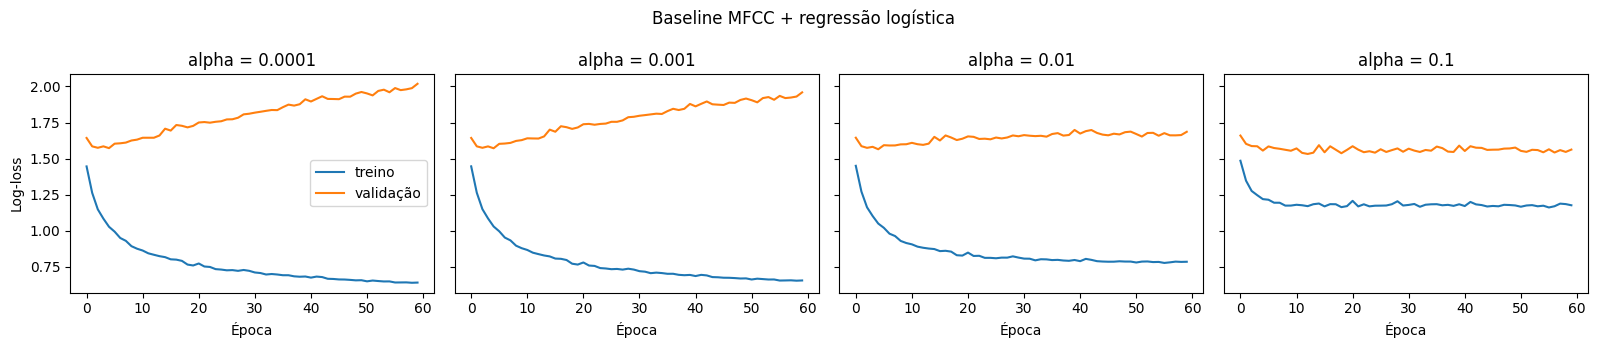

In [ ]:
ALPHAS = [1e-4, 1e-3, 1e-2, 1e-1]
CONDS = ["limpo", "20dB", "10dB", "0dB"]

resultados = []
fig, eixos = plt.subplots(1, len(ALPHAS), figsize=(4 * len(ALPHAS), 3.5), sharey=True)

for j, alpha in enumerate(ALPHAS):
    for i, seed in enumerate([0, 1, 2]):
        t0 = time.time()
        sc, clf, curva = treinar(seed, alpha)
        lim = escolher_limiar(sc, clf)
        tempo = time.time() - t0
        perda_val = curva[-1, 1]                 # log-loss de validação na última época
        for cond in CONDS:
            c = df.cond == cond
            f1, fa, fr = avaliar(sc, clf, lim, va_cmd & c, va_neg & c)
            resultados.append(dict(alpha=alpha, seed=seed, cond=cond, limiar=lim,
                                   logloss_val=perda_val, macroF1=f1, FA=fa, FR=fr, tempo_s=tempo))
        if i == 0:                               # curva da primeira semente de cada alpha
            ax = eixos[j]
            ax.plot(curva[:, 0], label="treino"); ax.plot(curva[:, 1], label="validação")
            ax.set_title(f"alpha = {alpha:g}"); ax.set_xlabel("Época")
    eixos[0].set_ylabel("Log-loss"); eixos[0].legend()

fig.suptitle("Baseline MFCC + regressão logística")
fig.tight_layout(); fig.savefig(f"{OUT}/curvas_alpha.png", dpi=200)

res = pd.DataFrame(resultados)
res.to_csv(f"{OUT}/resultados_val_alpha.csv", index=False)

resumo = (res.groupby(["alpha", "cond"])[["logloss_val", "macroF1", "FA", "FR", "tempo_s"]]
             .agg(["mean", "std"]))
print(resumo.round(3))

# Escolha do alpha: menor log-loss média de validação (só comandos)
melhor = res.groupby("alpha")["logloss_val"].mean().idxmin()
print(f"\nalpha escolhido na validação: {melhor:g}")

# Resultado
O teste inicial apresentou um resultado que era esperado com as médias da F1 caindo conforme o ruído aumentava, para o teste baseline utilizando regressão logística e escolhendo o limiar na validação após treinamento somente com comandos os resultados estão mostrados nas figuras abaixo:

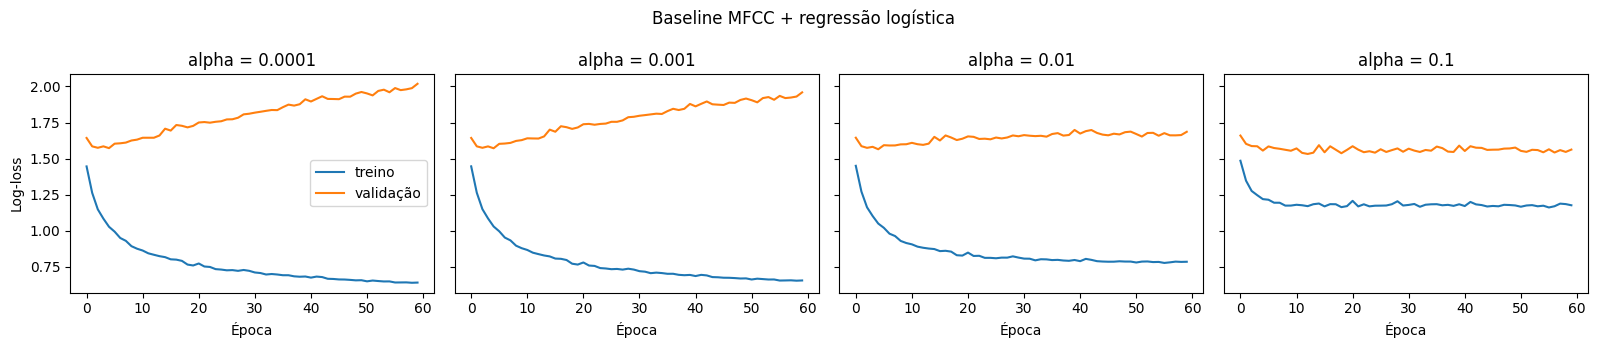

## Análise dos resultados
Para entendermos os resultados primeiro analisamos os gráficos gerados após o treinamento, visivelmente para os alphas menores houve overfitting e o modelo não generalizou, percebemos isso pela distanciação das curvas de treino e validação quanto a sua perda, o motivo desse overfitting vem do conjunto de dados que utilizamos momentaneamente:
```
audios   locutores   particao    tipo                       
teste    comando       36          3
         negativo      33         11
treino   comando       96          8
         negativo      99         33
val      comando       36          3
         negativo      33         11
```
Como estamos criando um dataset praticamente do zero e com pouco tempo, não conseguimos coletar um grande numero de vozes diferentes para cada um dos comandos, problema esse que com o prazo maior para a entrega do M3 poderá ser resolvido.
Por fim, na entrega final do projeto esperamos conseguir resultados mais conclusivos sobre o modelo, refazer o teste da baseline com mais locutores a fim de melhor ajustar o modelo aos diferentes conjuntos e, em seguida, desenvolver 2 modelos baseados em CNN, um deles trabalhando de acordo com o limiar, semelhante ao baseline, e outro modelo trabalhando com as classes negativas para medir o real impacto das duas abordagens.